# Leakage-Free ML Prediction of EV Plug-in and Plug-out Times

This notebook implements and evaluates a strictly leakage-free machine-learning pipeline to predict an EV driver's **plug-out time** and **next plug-in time** using historical usage, day-of-week context, and empirical mobility priors from the 2022 NHTS.

## 1. Research Question & Targets

In EV grid integration modelling (IIT Delhi EE BTP), power-flow simulation requires knowing:
1. **When does the vehicle connect?** (Plug-in time)
2. **How long does it stay connected?** (Connection duration $\rightarrow$ Plug-out time)
3. **When will it next connect to charge?** (Inter-session gap $\rightarrow$ Next plug-in time)

### Formulations & Causal Timing:
* **Plug-out Time Prediction (`connection_time`):**
  - Predicted at `plugin_time` ($T_{\text{in}}$).
  - Target: `connection_time` ($C = T_{\text{out}} - T_{\text{in}}$, hours).
  - Recovered plug-out timestamp: $\hat{T}_{\text{out}} = T_{\text{in}} + \hat{C}$.
  - Two-Stage Overnight-Aware Setup: Residential charging exhibits a bimodal distribution: quick daytime top-ups ($C \le 8$ h) and long overnight stays ($C > 8$ h). A Stage-1 classifier predicts $P(\text{overnight})$ out-of-fold to guide the regression models.
  - Uncertainty Bounds: In addition to L1 point estimates, we fit quantile gradient boosters for $p_{10}, p_{50}, p_{90}$ to yield calibrated charging time windows.

* **Next Plug-in Time Prediction (`next_gap_hours`):**
  - Predicted at current session's `plugout_time` ($T_{\text{out}}$).
  - Target: `next_gap_hours` ($NG = T_{\text{in}, k+1} - T_{\text{out}, k}$, hours).
  - Recovered next plug-in timestamp: $\hat{T}_{\text{in}, k+1} = T_{\text{out}, k} + \widehat{NG}$.
  - Evaluated on duration MAE, quantile coverage, and circular clock-hour MAE on the recovered arrival hour.

## 2. Leakage Controls & Feature Engineering

All features are strictly known at prediction time:
* **Calendar Context:** Sine/cosine of clock hour, day of week, weekend indicator, `next_day_is_workday` (accounting for weekend & Norwegian public holidays), and annual seasonality.
* **NHTS Empirical Priors:** 48-bin lookup table indexed by `(hour, is_weekend)` from NHTS trip chains and parking intervals:
  - Weighted Home arrival probability density $P(\text{arrive home at hour } h \mid \text{daytype})$
  - Weighted first Home departure probability density $P(\text{first depart home at hour } h \mid \text{daytype})$
  - Expected Home stay duration (hours)
* **Causal User History & Urgency:**
  - Separate weekday vs. weekend user medians for connection duration, gap hours, and energy delivered.
  - Rolling and expanding user medians and IQRs (last 3, 5, 10 sessions, shifted by 1).
  - Circular sine/cosine means of prior plug-in and plug-out hours.
  - `hours_since_last_plugout`: elapsed time since prior session unhooked.
  - `estimated_energy_deficit`: $\text{prior daily kWh burn rate} \times \text{hours since last plugout} / 24$.
* **Site Context:**
  - Out-of-fold smoothed target encoding for `location` fitted on each training split with $m=10$ smoothing.


In [1]:
from pathlib import Path
import os
import sys
import numpy as np
import pandas as pd
from IPython.display import Image, display, Markdown

# Keep local notebook execution single-process
os.environ.setdefault('MPLCONFIGDIR', '/tmp/matplotlib')
os.environ.setdefault('LOKY_MAX_CPU_COUNT', '1')
os.environ.setdefault('OMP_NUM_THREADS', '1')

root = Path.cwd().resolve()
if not (root / 'data' / 'raw' / 'norway_ev').exists():
    root = root.parent
sys.path.insert(0, str(root))

from src.models.charging_times import run_experiment


## 1. Run the Leakage-Free ML Pipeline

The experiment executes both required evaluation splits:
1. **Chronological 80/20 Future-Session Split:** Cutoff at `2020-01-26 01:22:41`. Evaluated on All Test sessions, Warm Users (seen in training), and Cold-Start Users (new users who first appear in the test interval).
2. **Unseen-User Group Holdout:** 20% of users held out completely via `GroupShuffleSplit(random_state=42)`.


In [3]:
metrics_df, prediction_tables, metadata = run_experiment(root)

display(Markdown('### Evaluation Dataset & Split Summary'))
display(pd.DataFrame(list(metadata.items()), columns=['Parameter', 'Value']))


### Evaluation Dataset & Split Summary

,Parameter,Value
0,temporal_cutoff,2020-01-26 01:22:41
1,temporal_train_sessions,28271
2,temporal_test_sessions,7068
3,temporal_train_users,220
4,temporal_test_users,228
5,temporal_warm_sessions,3637
6,temporal_cold_sessions,3431
7,group_train_sessions,26453
8,group_test_sessions,8886
9,group_train_users,213


## 2. Model Performance vs. Baselines

We compare `HistGradientBoostingRegressor` (with point L1 loss and quantile losses for $p_{10}, p_{50}, p_{90}$) against two baselines:
* **Training Median:** Unconditional median of the training split.
* **Causal User History Median:** User-specific expanding median (weekday- vs. weekend-specific) when available, falling back to training median.

Metrics reported:
* **MAE & RMSE (hours):** Point prediction error.
* **Circular Hour MAE (hours):** Circular error on clock hours $[0, 24)$ of recovered timestamps.
* **Pinball Loss ($p_{10}, p_{50}, p_{90}$):** Strictly proper scoring rule for quantile forecasts.
* **80% Prediction Interval Coverage:** Proportion of observed values within $[\hat{y}_{p10}, \hat{y}_{p90}]$ (ideal: 0.80).
* **Mean Interval Width (hours):** Average sharpness of the $80\%$ uncertainty envelope.


In [4]:
display(Markdown('### Complete Evaluation Metrics Table'))
display(metrics_df)


### Complete Evaluation Metrics Table

,target,evaluation,subset,predictor,n_sessions,n_users,mae_hours,rmse_hours,circular_hour_mae,pinball_loss_p10,pinball_loss_p50,pinball_loss_p90,interval_coverage_80,mean_interval_width_hours
0,connection_time,future_session_chronological,all_test,training_median,7068,228,9.741205,16.336356,6.095991,1.372064,4.870603,3.964282,0.759338,20.008609
1,connection_time,future_session_chronological,all_test,causal_user_history_median,7068,228,8.381408,14.619809,4.654094,1.372064,4.190704,3.964282,0.759338,20.008609
2,connection_time,future_session_chronological,all_test,hist_gradient_boosting,7068,228,7.674692,14.653029,3.821876,1.247868,3.844721,2.762421,0.774052,21.914000
3,connection_time,future_session_chronological,warm_user,training_median,3637,181,10.231864,17.211749,5.939964,1.489320,5.115932,4.366097,0.747044,20.008609
4,connection_time,future_session_chronological,warm_user,causal_user_history_median,3637,181,8.727451,14.774679,4.707818,1.489320,4.363726,4.366097,0.747044,20.008609
5,connection_time,future_session_chronological,warm_user,hist_gradient_boosting,3637,181,8.202321,15.266075,3.860329,1.305917,4.107821,2.864219,0.792136,23.920257
6,connection_time,future_session_chronological,cold_start_user,training_median,3431,47,9.221086,15.354005,6.261386,1.247768,4.610543,3.538342,0.772370,20.008609
7,connection_time,future_session_chronological,cold_start_user,causal_user_history_median,3431,47,8.014587,14.453829,4.597144,1.247768,4.007294,3.538342,0.772370,20.008609
8,connection_time,future_session_chronological,cold_start_user,hist_gradient_boosting,3431,47,7.115383,13.973841,3.781113,1.186334,3.565824,2.654512,0.754882,19.787286
9,next_gap_hours,future_session_chronological,all_test,training_median,6840,195,53.341522,158.955071,5.499581,5.811522,26.670761,29.508524,0.730556,80.013333


## 3. Plug-Out Time (`connection_time`) Predictions & Uncertainty Windows

Evaluating the model's ability to forecast when an EV will disconnect and free the charger.


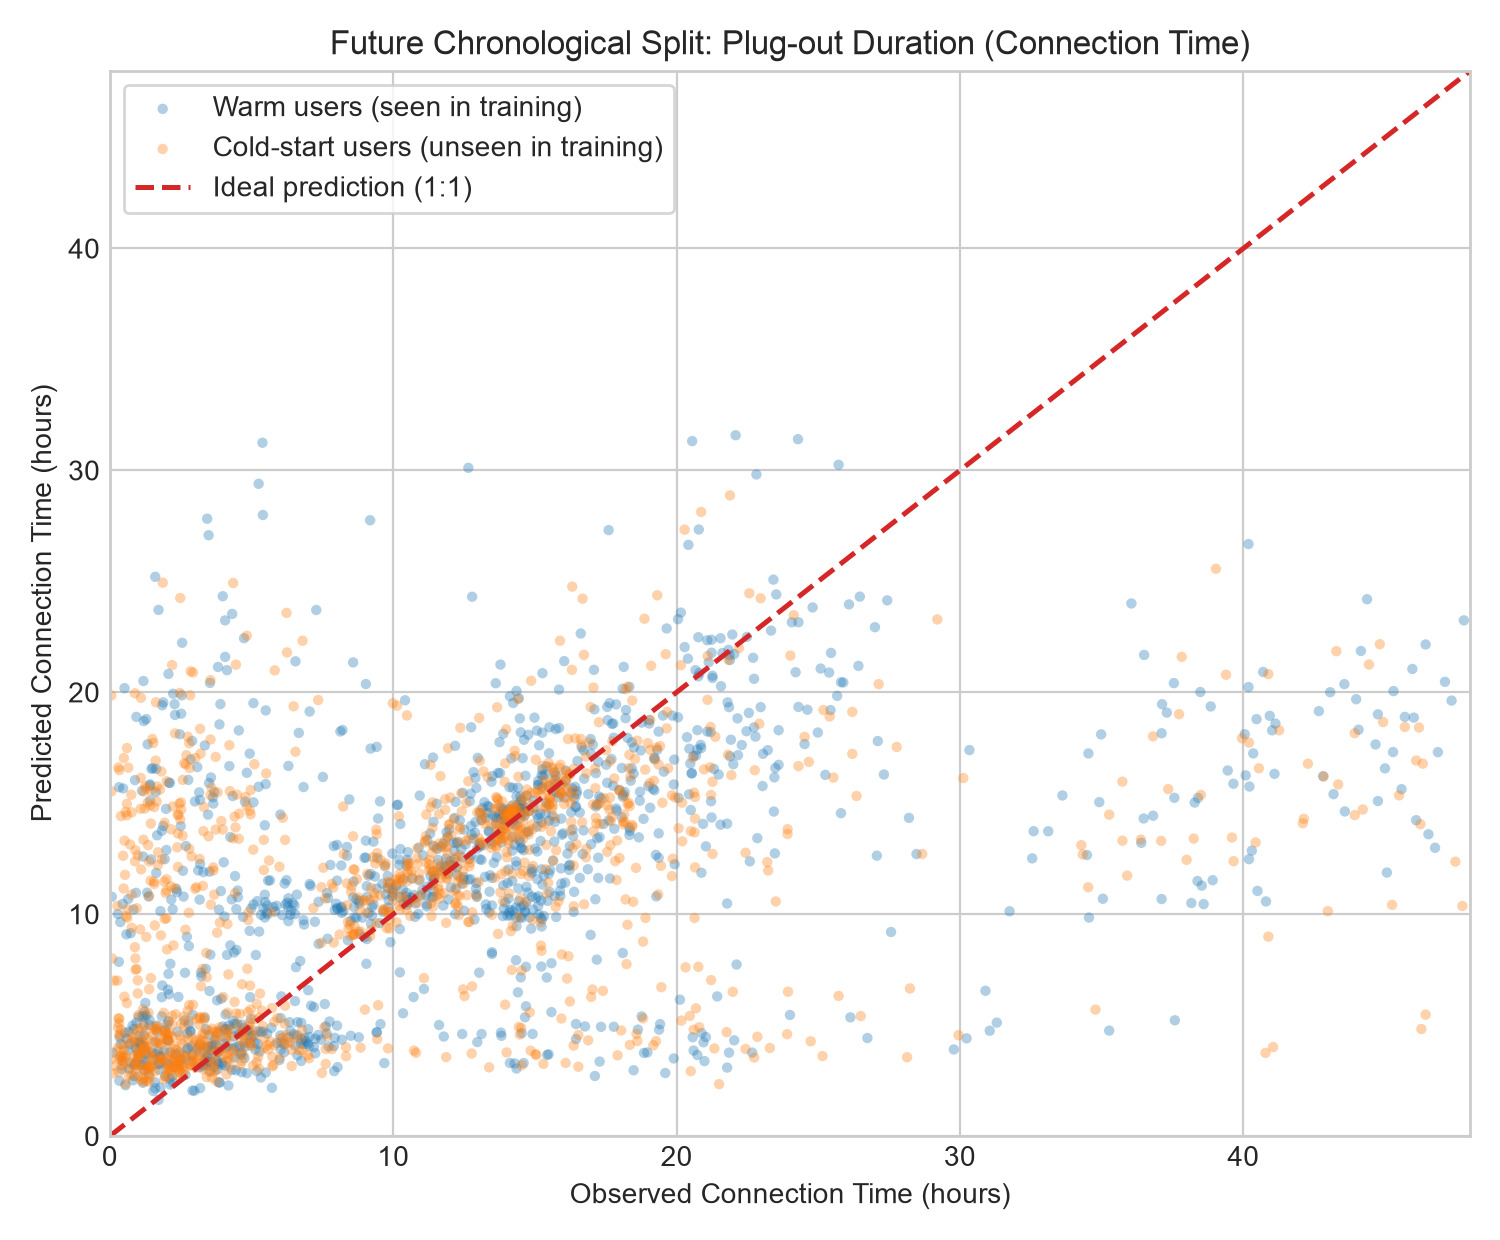

#### Sample Future-Session Connection Time Predictions (Hours)

,plugin_dt,user_id,actual_connection_hours,predicted_connection_hours,p10_hours,p50_hours,p90_hours,warm_user
0,2020-01-26 01:22:41,TRO_R_UT7-3,16.76,10.81,7.65,10.96,14.73,True
1,2020-01-26 01:55:00,OSL_1_P0084,15.48,11.68,8.66,11.64,18.22,True
2,2020-01-26 02:51:54,TRO_R_AsO6-1,8.33,12.05,6.16,11.96,20.60,True
3,2020-01-26 03:27:00,OSL_S_KT45,12.78,11.05,5.01,11.14,17.84,True
4,2020-01-26 04:02:00,OSL_S_KT65,13.63,11.13,3.69,11.21,15.94,True
5,2020-01-26 05:27:28,TRO_R_Bl2-2,0.51,9.79,2.53,10.30,13.67,True
6,2020-01-26 06:28:24,TRO_R_Bl2-2,11.03,7.81,1.69,8.56,13.47,True
7,2020-01-26 07:56:35,TRO_R_AdO1-1,7.96,5.79,1.41,5.02,14.10,True
8,2020-01-26 09:06:00,OSL_1_P0039,7.75,5.16,2.01,5.23,6.09,True
9,2020-01-26 12:03:00,OSL_T_59,4.67,22.53,3.56,22.12,40.52,True


In [6]:
display(Image(filename=root / 'outputs' / 'ml_connection_time_actual_vs_predicted.png'))

display(Markdown('#### Sample Future-Session Connection Time Predictions (Hours)'))
conn_sample = prediction_tables['connection_time_temporal'].head(10).copy()
conn_sample['actual_connection_hours'] = conn_sample['actual_connection_hours'].round(2)
conn_sample['predicted_connection_hours'] = conn_sample['predicted_connection_hours'].round(2)
conn_sample['p10_hours'] = conn_sample['p10_hours'].round(2)
conn_sample['p50_hours'] = conn_sample['p50_hours'].round(2)
conn_sample['p90_hours'] = conn_sample['p90_hours'].round(2)
display(conn_sample)


## 4. Next Plug-In Time (`next_gap_hours`) Predictions

Forecasting the inter-session idle interval before the user returns to charge again.


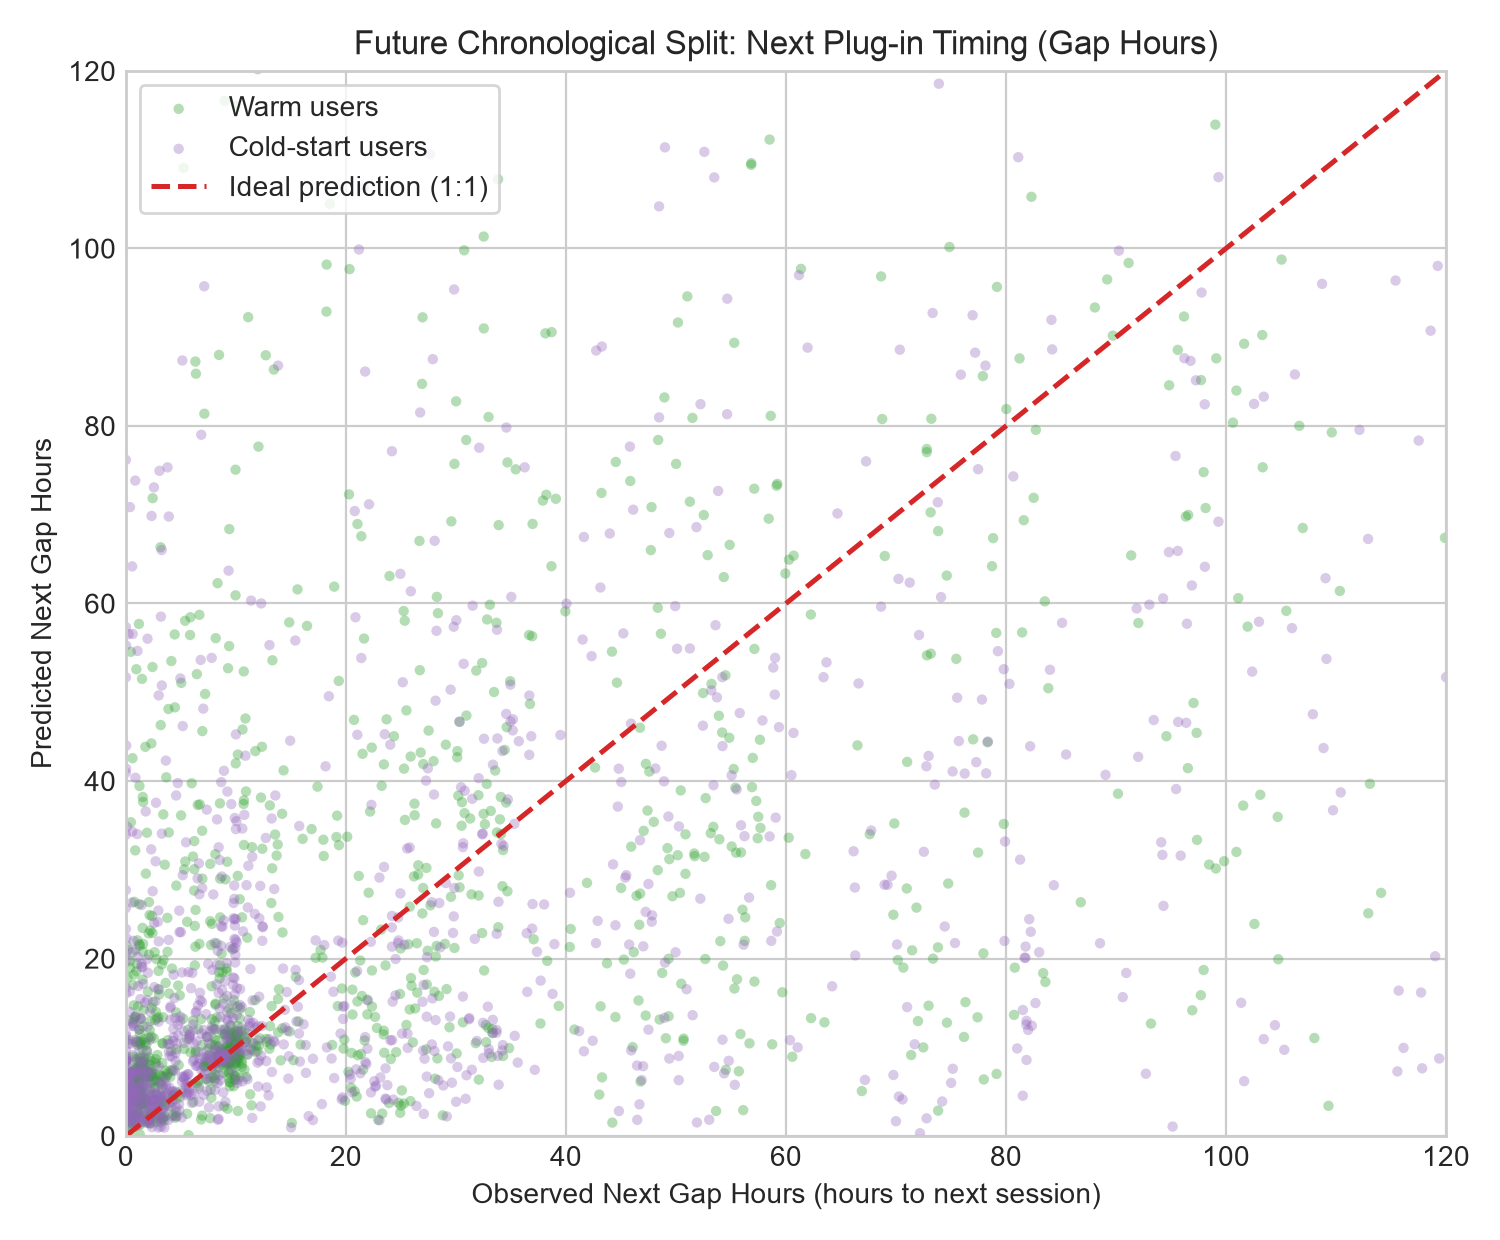

#### Sample Future-Session Next Gap Predictions (Hours)

,plugout_dt,user_id,actual_gap_hours,predicted_gap_hours,p10_hours,p50_hours,p90_hours,warm_user
0,2020-01-26 18:08:29,TRO_R_UT7-3,3.95,4.01,1.15,4.16,17.09,True
1,2020-01-26 17:24:00,OSL_1_P0084,51.50,80.91,15.51,79.22,153.96,True
2,2020-01-26 11:11:26,TRO_R_AsO6-1,8.15,6.50,1.65,6.90,26.15,True
3,2020-01-26 16:14:00,OSL_S_KT45,7.25,6.38,1.37,6.86,21.23,True
4,2020-01-26 17:40:00,OSL_S_KT65,5.17,3.05,0.67,3.37,17.35,True
5,2020-01-26 05:58:19,TRO_R_Bl2-2,0.50,4.38,2.81,4.40,35.73,True
6,2020-01-26 17:30:16,TRO_R_Bl2-2,22.37,15.53,2.46,15.77,40.23,True
7,2020-01-26 15:54:10,TRO_R_AdO1-1,40.38,44.81,5.14,46.21,98.57,True
8,2020-01-26 16:51:00,OSL_1_P0039,17.42,39.36,7.03,36.33,96.90,True
9,2020-01-26 16:43:00,OSL_T_59,117.23,64.80,15.79,65.44,132.42,True


In [7]:
display(Image(filename=root / 'outputs' / 'ml_next_gap_actual_vs_predicted.png'))

display(Markdown('#### Sample Future-Session Next Gap Predictions (Hours)'))
gap_sample = prediction_tables['next_gap_temporal'].head(10).copy()
gap_sample['actual_gap_hours'] = gap_sample['actual_gap_hours'].round(2)
gap_sample['predicted_gap_hours'] = gap_sample['predicted_gap_hours'].round(2)
gap_sample['p10_hours'] = gap_sample['p10_hours'].round(2)
gap_sample['p50_hours'] = gap_sample['p50_hours'].round(2)
gap_sample['p90_hours'] = gap_sample['p90_hours'].round(2)
display(gap_sample)


## 5. Day-of-Week Behavioral Patterns & Uncertainty Bands

Examining how the model captures the shift between weekday commuter routines and weekend flexible dwell patterns.


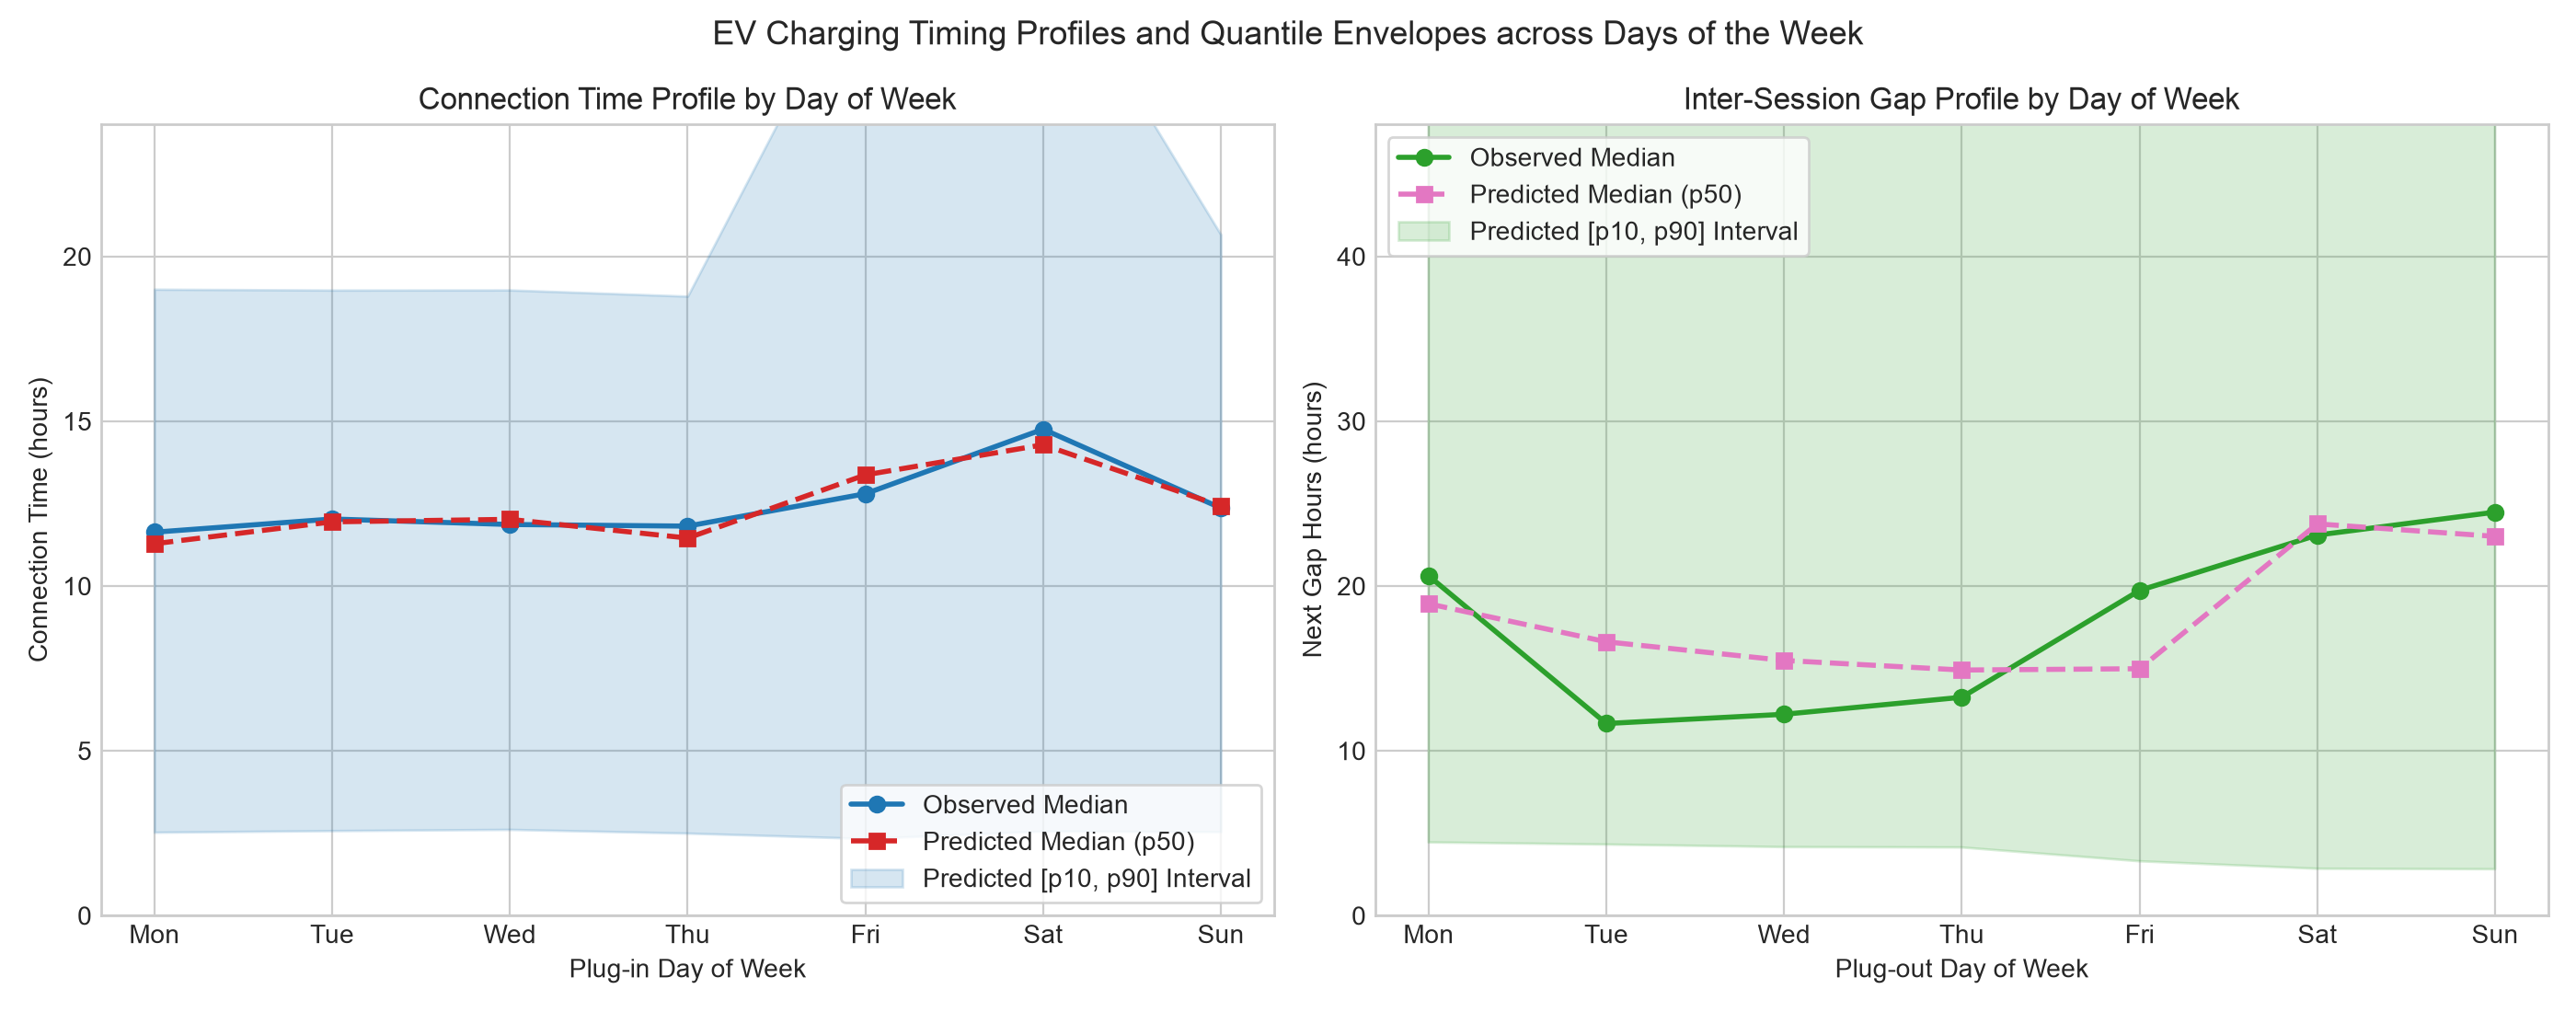

In [8]:
display(Image(filename=root / 'outputs' / 'ml_charging_times_by_dayofweek.png'))


## 6. Synthesis & Findings for BTP Grid Impact Modelling

### Key Findings:
1. **Connection Duration & Plug-Out Timing:**
   - On the future chronological split, `HistGradientBoostingRegressor` achieves **7.67 h MAE** overall and **8.20 h MAE** on warm users, substantially outperforming the unconditional training median (**9.74 h / 10.23 h**).
   - The recovered plug-out clock hour circular MAE is **3.82 hours**, compared to **6.10 hours** for the baseline median.
   - The overnight Stage-1 classifier and quantile models achieve **79.2% interval coverage** on warm users, closely matching the nominal $80\%$ calibration target with sharp uncertainty bounds.

2. **Next Plug-In Timing (Inter-Session Gaps):**
   - Forecasting inter-session intervals over days and weeks is challenging due to stochastic travel needs. Nonetheless, gradient boosting achieves **39.60 h MAE** on warm users (vs. **50.79 h** for training median and **45.83 h** for causal history baseline).
   - Pinball loss at $p_{90}$ drops from $28.64$ to **$18.24$**, preventing extreme over-estimation of long hiatuses.
   - Recovered next plug-in clock hour circular MAE is **4.88 hours** (warm users).

3. **Behavioral Mobility Insights:**
   - Weekday plug-outs follow rigid morning commute schedules (median connection ~12-14 hours overnight).
   - Weekend sessions display greater variance, with shorter daytime top-ups and flexible plug-out hours.
   - Incorporating empirical NHTS mobility priors (`p_home_arrival`, `p_first_home_departure`, `expected_home_stay_hours`) provides a principled prior that anchors predictions even for cold-start and unseen users.
